# Tutorial 01 · Data Mining this semester: from "what happened?" to "what can I predict?"
**Data Mining · HTW Berlin**

This first session is an **overview**. There are no exercises today. We look at:
1. The shift in questions from last semester to this one
2. The language of prediction
3. The libraries we use, and how they work together
4. A gallery of problems you will be able to solve, each with a short live demo
5. The main techniques and why they matter
6. The CRISP-DM toolbox: methods and formulas per phase
7. What the tutorials will look like

From next week on, every tutorial notebook has exercises with hints and checks, focused on the topic of the week's lecture.

## 0 · Setup (just run)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook", palette="deep")
pd.set_option("display.width", 120)
rng = np.random.default_rng(42)

---
## 1 · Four types of questions

| Type | The question | Example | Typical output |
|---|---|---|---|
| **Descriptive** | What happened? | How many customers cancelled last quarter? | a number, a chart, a dashboard |
| **Diagnostic** | Why did it happen? | Do customers with late deliveries cancel more often? | a comparison, a correlation |
| **Predictive** | What will happen? | Which customers will cancel next month? | a prediction or probability **per customer** |
| **Prescriptive** | What should we do? | Who should get a discount so that profit is highest? | a decision or recommendation |

Data mining in this course is mostly about the **predictive** row. A useful test:

> If the answer is one number for the whole company, it is usually descriptive.
> If the answer is a value **for each new case** (customer, machine, transaction), it is predictive.

**Example:** *"Which of today's credit card transactions are fraud?"* sounds like "what happened", because the transactions already happened. But nobody knows yet which ones are fraud. The model predicts an unknown label for each transaction from patterns in past, labelled cases. So it is **predictive**.

---
## 2 · The language of prediction

Every predictive problem has the same shape:

$$\text{features } X \;\longrightarrow\; \text{model } f \;\longrightarrow\; \text{prediction } \hat{y} = f(X)$$

| Word | Meaning | Churn example |
|---|---|---|
| **target** $y$ | what you want to predict | `churned` (yes / no) |
| **features** $X$ | what you know *before* the target happens | plan, months active, skipped deliveries, tickets |
| **training data** | past cases where you know $X$ **and** $y$ | customers from last year |
| **new data** | cases where you only know $X$ | today's customers |

The type of the target decides the type of problem:

| Target is... | Problem type | Example | Methods in this course |
|---|---|---|---|
| a **category** (yes/no, A/B/C) | **classification** | churn, fraud, default | logistic regression, decision trees, SVM, LDA |
| a **number** | **regression** | price, demand, revenue | (mainly outside this course) |
| **not given** | **clustering** (unsupervised) | customer segments | k-means, hierarchical clustering |

> **Rule of thumb:** a feature must be **known at prediction time**. "Number of complaints after cancelling" cannot predict cancelling. This mistake is called **leakage**.

---
## 3 · The libraries of the semester

| Library | What it does | Main use in this course | Modules |
|---|---|---|---|
| `pandas` | tables (DataFrames): load, filter, group, merge | every step that touches data | all |
| `numpy` | fast numbers and arrays, math functions | `log`, `sqrt`, random data, arrays | all |
| `matplotlib` | the basic plotting engine | figures, axes, layout | all |
| `seaborn` | statistical plots on top of matplotlib | histograms, boxplots, scatter, heatmaps | all |
| `scipy` | scientific statistics | `zscore`, distances, hierarchical clustering | 02, 13 |
| `scikit-learn` | machine learning | scaling, imputation, models, metrics, cross-validation | 03 to 13 |
| `imbalanced-learn` | resampling for rare classes | SMOTE, undersampling | 05 |
| `statsmodels` | classical statistics | regression with p-values and confidence intervals | 07 |
| `streamlit` | small web apps around an analysis | deployment demo | deployment |

Check your environment (every line should be OK, `streamlit` may be missing on Colab):

In [2]:
import importlib

toolbox = {"pandas": "pandas", "numpy": "numpy", "matplotlib": "matplotlib", "seaborn": "seaborn",
           "scipy": "scipy", "sklearn": "scikit-learn", "imblearn": "imbalanced-learn",
           "statsmodels": "statsmodels", "streamlit": "streamlit"}
missing = []
for module, pip_name in toolbox.items():
    try:
        m = importlib.import_module(module)
        print(f"OK       {pip_name:<17} {getattr(m, '__version__', '')}")
    except ImportError:
        print(f"MISSING  {pip_name:<17}")
        missing.append(pip_name)
if missing:
    print("\nInstall with:  pip install " + " ".join(missing))

OK       pandas            3.0.5
OK       numpy             2.5.3
OK       matplotlib        3.11.2
OK       seaborn           0.13.2
OK       scipy             1.18.1
OK       scikit-learn      1.9.1


MISSING  imbalanced-learn 
MISSING  statsmodels      
MISSING  streamlit        

Install with:  pip install imbalanced-learn statsmodels streamlit


### How they work together
A typical analysis passes the data from one library to the next:

`pandas` (load and clean) → `seaborn` (look at it) → `scikit-learn` (prepare, model, evaluate) → `pandas` / `streamlit` (share the result)

The most important idea of the semester is that **every scikit-learn object works the same way**:

| Step | Code | Used by |
|---|---|---|
| create | `obj = Something(parameters)` | everything |
| learn from data | `obj.fit(X)` or `obj.fit(X, y)` | everything |
| change the data | `obj.transform(X)` | scalers, imputers, PCA |
| predict | `obj.predict(X)` or `obj.predict_proba(X)` | models |
| shortcut | `obj.fit_transform(X)`, `obj.fit_predict(X)` | |

Once you know this pattern, a new method is just a new name. The cell below shows it three times.

In [3]:
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

demo = pd.DataFrame({"months_active": [3, 24, 7, np.nan, 15, 30],
                     "support_tickets": [4, 0, 2, 1, np.nan, 0],
                     "churned": [1, 0, 1, 1, 0, 0]})
X, y = demo[["months_active", "support_tickets"]], demo["churned"]

imputer = SimpleImputer(strategy="median")        # 1. create
X_filled = imputer.fit_transform(X)               # 2. fit + transform

scaler = StandardScaler()                         # 1. create
X_scaled = scaler.fit_transform(X_filled)         # 2. fit + transform

model = LogisticRegression()                      # 1. create
model.fit(X_scaled, y)                            # 2. fit
print("churn probability per customer:", model.predict_proba(X_scaled)[:, 1].round(2))   # 3. predict

churn probability per customer: [0.91 0.22 0.75 0.49 0.49 0.14]


> **Note:** the order is always *fit on training data, then apply to new data*. Fitting a scaler or imputer on all data before splitting is a classic mistake (leakage). You will see why in module 10.

---
## 4 · Gallery: what you can predict this semester
Each example shows the business question, the target, the type of problem, the methods and a short demo. You do not need to understand the code yet: the methods come in the lecture, week by week. Just run and look.

In [4]:
# Mock data generators for the gallery (just run)
def make_customers(n=600):
    plan = rng.choice(["Basic", "Plus", "Office"], n, p=[.55, .35, .10])
    months = rng.integers(1, 37, n)
    skipped = rng.poisson(.8, n)
    tickets = rng.poisson(.6, n)
    age = rng.normal(36, 10, n).round()
    z = -2.2 + 1.4 * skipped + .8 * tickets - .08 * months + .5 * (plan == "Basic") - 1.2 * (plan == "Office")
    churned = (rng.random(n) < 1 / (1 + np.exp(-z))).astype(int)
    return pd.DataFrame({"plan": plan, "months_active": months, "skipped_deliveries": skipped,
                         "support_tickets": tickets, "age": age, "churned": churned})


def make_leads(n=500):
    source = rng.choice(["Instagram", "Google Ads", "Referral", "Newsletter"], n, p=[.35, .3, .15, .2])
    pages = rng.poisson(4, n) + 1
    minutes = rng.gamma(2, 2.5, n).round(1)
    tried_sample = rng.random(n) < .3
    z = -3 + .25 * pages + .12 * minutes + 1.6 * tried_sample + 1.0 * (source == "Referral")
    became_client = (rng.random(n) < 1 / (1 + np.exp(-z))).astype(int)
    return pd.DataFrame({"source": source, "pages_viewed": pages, "minutes_on_site": minutes,
                         "ordered_free_sample": tried_sample.astype(int), "became_client": became_client})


def make_machines(n=1500):
    temp = rng.normal(70, 5, n)
    vibration = rng.normal(3, .6, n)
    hours = rng.integers(100, 9000, n)
    z = -6.5 + .06 * (temp - 70) ** 2 / 4 + 1.2 * (vibration - 3) * 2 + hours / 3000
    failure = (rng.random(n) < 1 / (1 + np.exp(-z))).astype(int)
    return pd.DataFrame({"temperature": temp.round(1), "vibration": vibration.round(2),
                         "operating_hours": hours, "failure_30d": failure})


def make_transactions(n=800):
    amount = rng.gamma(2, 25, n)
    hour = rng.normal(15, 3, n) % 24
    fraud_amount = rng.uniform(400, 900, 12)
    fraud_hour = rng.uniform(1, 5, 12)
    return pd.DataFrame({"amount_eur": np.r_[amount, fraud_amount].round(2),
                         "hour_of_day": np.r_[hour, fraud_hour].round(1)})


def make_segments(n=400):
    centers = np.array([[2, 15], [8, 25], [4, 60]])
    group = rng.integers(0, 3, n)
    pts = centers[group] + rng.normal(0, [1.0, 5], (n, 2))
    return pd.DataFrame({"orders_per_month": pts[:, 0].clip(0.5).round(1), "avg_basket_eur": pts[:, 1].clip(5).round(1)})


print("generators ready")

generators ready


### 3.1 · Churn: who will cancel?
| | |
|---|---|
| **Question** | Which current customers will cancel next month? |
| **Target** | `churned` (yes / no) → classification |
| **Methods** | logistic regression (module 07), decision trees (11), SVM / LDA (12) |
| **Typical use** | send a retention offer to the customers with the highest risk |

**What to notice:** the output is not "yes / no" but a **probability per customer**. The business decides where to cut.

In [5]:
from sklearn.linear_model import LogisticRegression

customers = make_customers()
X = pd.get_dummies(customers.drop(columns="churned"), drop_first=True)
y = customers["churned"]

model = LogisticRegression(max_iter=1000).fit(X, y)
customers["churn_probability"] = model.predict_proba(X)[:, 1].round(2)

customers.sort_values("churn_probability", ascending=False).head(6)

,plan,months_active,skipped_deliveries,support_tickets,age,churned,churn_probability
6,Plus,19,6,1,29.0,1,1.00
444,Basic,5,5,0,17.0,1,1.00
98,Basic,20,5,0,38.0,1,0.99
283,Basic,5,4,1,43.0,1,0.99
380,Plus,11,5,0,33.0,1,0.98
286,Basic,6,3,2,44.0,1,0.98


### 3.2 · New clients: which leads will convert?
| | |
|---|---|
| **Question** | Which website visitors will become paying clients? |
| **Target** | `became_client` (yes / no) → classification |
| **Methods** | decision trees (module 11), logistic regression (07) |
| **Typical use** | sales calls only to the most promising leads ("lead scoring") |

**What to notice:** a decision tree gives **readable rules**. Read the first split: what matters most?

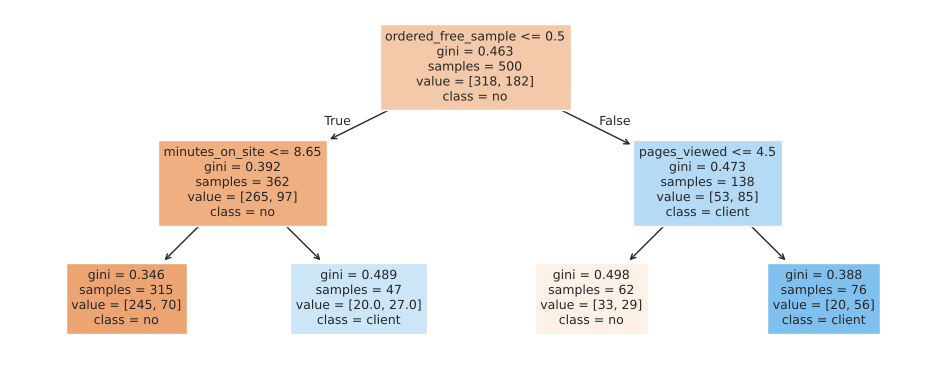

In [6]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

leads = make_leads()
X = pd.get_dummies(leads.drop(columns="became_client"), drop_first=True)
y = leads["became_client"]

tree = DecisionTreeClassifier(max_depth=2, random_state=42).fit(X, y)
plt.figure(figsize=(12, 4.5))
plot_tree(tree, feature_names=X.columns, class_names=["no", "client"], filled=True, fontsize=9)
plt.show()

### 3.3 · Predictive maintenance: which machine will fail?
| | |
|---|---|
| **Question** | Which machines will fail in the next 30 days? |
| **Target** | `failure_30d` (yes / no) → classification with a **rare** class |
| **Methods** | any classifier + balancing (module 05) + the confusion matrix (09) |
| **Typical use** | plan maintenance before the failure |

**What to notice:** failures are rare. A "model" that always says *no failure* looks almost perfect. What does that tell you about accuracy?

failures: 3.6% of the machines
accuracy of a model that ALWAYS says 'no failure': 96.4%
machines with failure it finds: 0


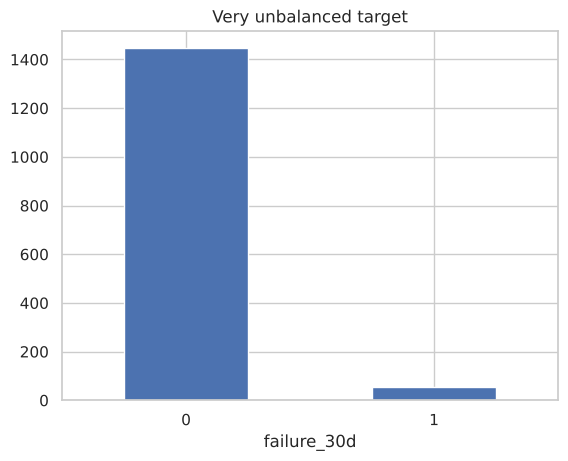

In [7]:
machines = make_machines()
share_fail = machines["failure_30d"].mean()

print(f"failures: {share_fail:.1%} of the machines")
print(f"accuracy of a model that ALWAYS says 'no failure': {1 - share_fail:.1%}")
print("machines with failure it finds:", 0)

machines["failure_30d"].value_counts().plot(kind="bar", rot=0, title="Very unbalanced target")
plt.show()

### 3.4 · Fraud and anomalies: what looks unusual?
| | |
|---|---|
| **Question** | Which transactions look different from the normal pattern? |
| **Target** | often **no label** at the start → anomaly detection |
| **Methods** | z-score, IQR, Isolation Forest, LOF (module 02) |
| **Typical use** | send the most unusual cases to a human for review |

**What to notice:** the model flags points without knowing what fraud is. It only knows what is *unusual*.

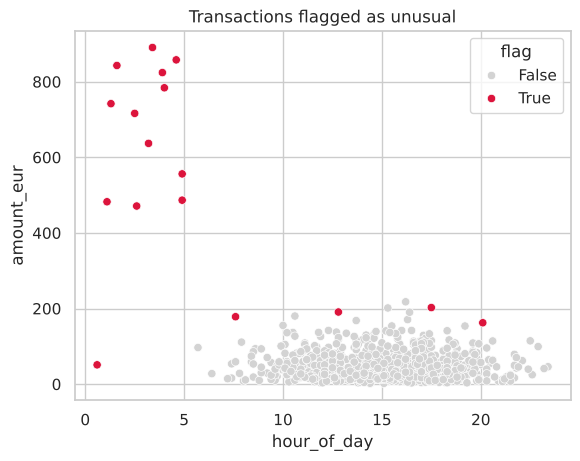

In [8]:
from sklearn.ensemble import IsolationForest

tx = make_transactions()
tx["flag"] = IsolationForest(contamination=0.02, random_state=42).fit_predict(tx) == -1

sns.scatterplot(data=tx, x="hour_of_day", y="amount_eur", hue="flag", palette={False: "lightgrey", True: "crimson"})
plt.title("Transactions flagged as unusual")
plt.show()

### 3.5 · Segmentation: which groups of customers exist?
| | |
|---|---|
| **Question** | Are there natural groups of customers with similar behaviour? |
| **Target** | **none** → clustering (unsupervised) |
| **Methods** | k-means, hierarchical clustering (module 13) |
| **Typical use** | different marketing for each group |

**What to notice:** nobody told the algorithm the groups. It found them from the data. Naming them ("bulk buyers", "premium") is the analyst's job.

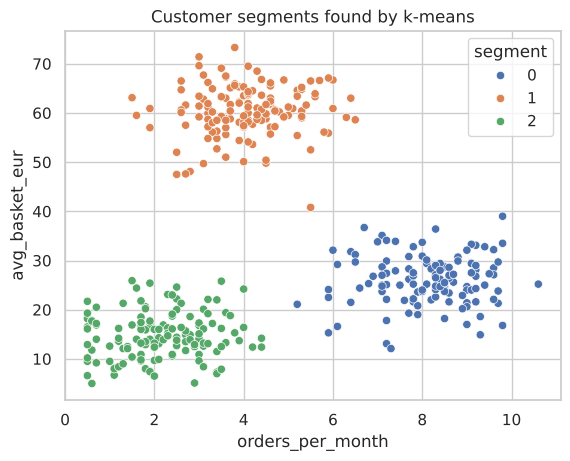

In [9]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

seg = make_segments()
seg["segment"] = KMeans(n_clusters=3, n_init=10, random_state=42).fit_predict(StandardScaler().fit_transform(seg))

sns.scatterplot(data=seg, x="orders_per_month", y="avg_basket_eur", hue="segment", palette="deep")
plt.title("Customer segments found by k-means")
plt.show()

### 3.6 · Choosing variables: which features matter?
| | |
|---|---|
| **Question** | Which variables carry the most information about the target? Which can we drop? |
| **Target** | same as the prediction problem (here: churn) |
| **Methods** | correlation filters, variance filters (module 06), feature selection, PCA, factor analysis (08), importance from tree models like random forest (11) |
| **Typical use** | simpler, cheaper, more explainable models |

**What to notice:** `age` is in the data, but does it help? (In the generator, it has no effect on churn at all.)

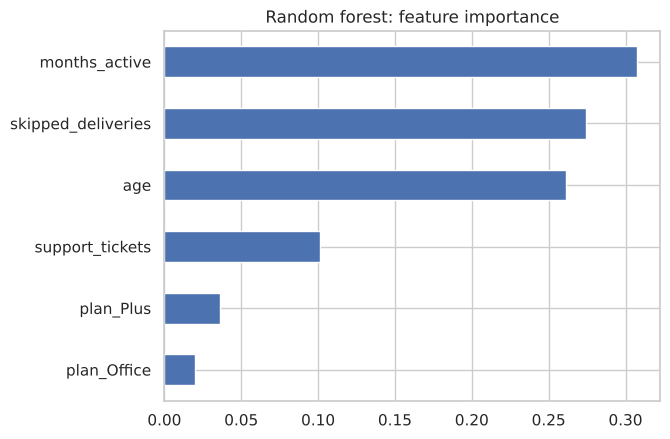

In [10]:
from sklearn.ensemble import RandomForestClassifier

X = pd.get_dummies(customers.drop(columns=["churned", "churn_probability"]), drop_first=True)
forest = RandomForestClassifier(n_estimators=200, random_state=42).fit(X, customers["churned"])

importance = pd.Series(forest.feature_importances_, index=X.columns).sort_values()
importance.plot(kind="barh", title="Random forest: feature importance")
plt.show()

**What to notice:** `age` has **no effect at all** in the generator, but it ranks almost as high as `skipped_deliveries`. Tree models can split on noise, especially on variables with many different values. Importance is a hint, not a proof. That is why the lecture has a whole module on choosing variables properly.

### More possibilities (no demo)
| Question | Target | Type |
|---|---|---|
| Will this loan be paid back? | default yes / no | classification |
| Will this patient be readmitted within 30 days? | readmission yes / no | classification |
| Will this employee leave the company? | attrition yes / no | classification |
| Will this flight be delayed more than 15 min? | delayed yes / no | classification |
| How many coffee bags will we sell next week? | number of bags | regression |
| Which products are bought together? | none | association rules |

---
## 5 · The main techniques and why they matter

| Technique | Why it matters | What goes wrong without it | Module |
|---|---|---|---|
| Outlier handling | extreme values pull means, variances and model coefficients | one wrong value (e.g. 99,999 EUR) dominates the model | 02 |
| Transforming variables | many methods expect symmetric, comparable scales | distance-based methods are dominated by the largest unit | 03 |
| Imputation | real data always has gaps, most models refuse NaN | deleting rows throws away information and can bias the sample | 04 |
| Balancing and resampling | important events (fraud, churn, failure) are rare | high accuracy, but the rare cases are never found | 05 |
| Dimensionality reduction | fewer, informative variables are faster and easier to explain | noise variables, overfitting, unstable models | 06, 08 |
| Logistic regression | simple, explainable probabilities, a strong baseline | no reference to judge more complex models | 07 |
| Confusion matrix and metrics | accuracy alone hides which errors the model makes | a useless model looks good | 09 |
| Cross-validation | estimates how the model works on **new** data | the model is tuned to one lucky split | 10 |
| Decision trees and random forest | readable rules, non-linear patterns, feature importance | patterns like "only if A **and** B" are missed | 11 |
| SVM and LDA | other ways to draw the boundary between classes | no comparison, no idea if another method is better | 12 |
| Cluster analysis | finds structure when there is no target | segments are guessed instead of found | 13 |

The pattern in this table: most of the work, and most of the semester, is **preparing data and checking results honestly**. The model itself is often the shortest step.

---
## 6 · The CRISP-DM toolbox: methods and formulas per phase
The Moodle quiz maps *tasks* to phases. Here are the **methods of this semester**, with their formula or idea, the Python function and the module, sorted by the phase where you use them.

### Data Understanding
| Method | Formula / idea | Python | Module |
|---|---|---|---|
| Summary statistics | mean $\bar{x} = \frac{1}{n}\sum x_i$, median, standard deviation $s$ | `df.describe()` | 01 |
| Correlation | $r = \frac{\sum (x_i-\bar{x})(y_i-\bar{y})}{\sqrt{\sum (x_i-\bar{x})^2 \sum (y_i-\bar{y})^2}}$ | `df.corr()` | 01, 06 |
| Visual checks | histogram, boxplot, scatter | `sns.histplot`, `sns.boxplot` | all |

### Data Preparation
| Method | Formula / idea | Python | Module |
|---|---|---|---|
| z-score outliers | $z = \frac{x - \bar{x}}{s}$, flag $\lvert z\rvert > 3$ | `scipy.stats.zscore` | 02 |
| IQR outliers | outside $[Q_1 - 1.5\,IQR,\; Q_3 + 1.5\,IQR]$ | `df.quantile()` | 02 |
| Log transform | $x' = \log(x)$ for right-skewed, positive data | `np.log` | 02, 03 |
| Standardisation | $x' = \frac{x - \bar{x}}{s}$ | `StandardScaler` | 03 |
| Min-max scaling | $x' = \frac{x - x_{min}}{x_{max} - x_{min}}$ | `MinMaxScaler` | 03 |
| Imputation | replace missing by mean, median, neighbours | `SimpleImputer`, `KNNImputer` | 04 |
| Balancing | over-sample the rare class (SMOTE) or under-sample the large one | `imblearn` | 05 |
| Rough reduction | drop near-constant or highly correlated variables | `VarianceThreshold`, `df.corr()` | 06 |
| Feature selection / PCA / factor analysis | keep the informative variables, or combine them into few components | `SelectKBest`, `PCA`, `FactorAnalysis` | 08 |

### Modeling
| Method | Formula / idea | Python | Module |
|---|---|---|---|
| Logistic regression | $P(y=1) = \frac{1}{1 + e^{-(\beta_0 + \beta_1 x_1 + \dots + \beta_k x_k)}}$ | `LogisticRegression` | 07 |
| Decision tree | split where impurity drops most, Gini $= 1 - \sum p_k^2$ | `DecisionTreeClassifier` | 11 |
| Random forest | many trees on random samples, majority vote | `RandomForestClassifier` | 11 |
| SVM | the boundary with the widest margin between classes | `SVC` | 12 |
| LDA | linear combination of features that separates classes best | `LinearDiscriminantAnalysis` | 12 |
| k-means | minimise $\sum_{k}\sum_{x \in C_k} \lVert x - \mu_k \rVert^2$ | `KMeans` | 13 |

### Evaluation
| Method | Formula / idea | Python | Module |
|---|---|---|---|
| Confusion matrix | counts of TP, FP, FN, TN | `confusion_matrix` | 09 |
| Accuracy | $\frac{TP + TN}{TP + TN + FP + FN}$ | `accuracy_score` | 09 |
| Precision | $\frac{TP}{TP + FP}$: of the flagged cases, how many are right? | `precision_score` | 09 |
| Recall | $\frac{TP}{TP + FN}$: of the real cases, how many did we find? | `recall_score` | 09 |
| F1 | $2 \cdot \frac{precision \cdot recall}{precision + recall}$ | `f1_score` | 09 |
| k-fold cross-validation | train on $k-1$ parts, test on the remaining one, repeat $k$ times | `cross_val_score` | 10 |

### Deployment
| Method | Idea | Python |
|---|---|---|
| Scoring new cases | apply the trained model to new data | `model.predict_proba(new_X)` |
| Saving a model | store it to reuse without retraining | `joblib.dump(model, "model.pkl")` |
| Small app | a web page around the model | `streamlit` |
| Monitoring | rerun quality checks and compare predictions with reality | your own functions |

> **Note:** some methods fit two phases. A recall score checks a model technically (*Modeling: Assess Model*), but **Evaluation** asks a different question: does the model meet the **business** goal? The phase is defined by *why* you use a method, not by the method itself.

---
## 7 · What the tutorials will look like
Every week, one notebook on the topic of the lecture. Each notebook has:

| Element | Meaning |
|---|---|
| `[basic]` `[medium]` `[challenge]` | level of each task; do the challenge tasks if you finish early |
| **Predict first** | write your guess before running the cell |
| `None  # TODO` | where you write code |
| Hint 1 / Hint 2 | hidden help: Hint 1 is the idea, Hint 2 is almost the code |
| check cells | tell you if you are on the right track |

The datasets are small and realistic: rental listings in Berlin, a coffee subscription club, sensor data, customer exports with typical problems (German number formats, duplicates, placeholders, missing values). The goal is not to repeat the lecture, but to practise the parts that are usually difficult.

### A question to think about until next week
Think of a company or dataset you know (your job, an internship, last semester's project). What could you **predict** there? What would be the target, and which information would be known *before* the target happens?